In [1]:
import os
import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio
from rasterio.mask import mask
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import joblib

DATA_DIR = "/kaggle/input/datasets/minatonamikaze20/karnal-rabi"
OUT_DIR = "/kaggle/working"
os.makedirs(OUT_DIR, exist_ok=True)

BOUNDARY_SHP   = os.path.join(DATA_DIR, "Karnal_Boundary.shp")
RABI_RASTER    = os.path.join(DATA_DIR, "Karnal_Rabi_SelectedBands.tif")
TRAINING_CSV   = os.path.join(DATA_DIR, "Karnal_Rabi_Training_Data.csv")

print(os.listdir(DATA_DIR))

['Karnal_Rabi_Training_Data.csv', 'Karnal_Boundary.shp', 'Karnal_Boundary.cpg', 'Karnal_Boundary.prj', 'Karnal_Boundary.shx', 'Karnal_Boundary.fix', 'Karnal_Boundary.dbf', 'Karnal_Rabi_SelectedBands.tif']


EPSG:4326 (1, 13)


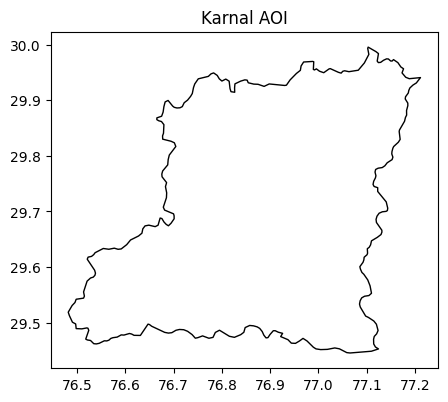

CRS: EPSG:4326
Size: 8118 6122
Band count: 6
Descriptions: ('B2', 'B3', 'B4', 'B8', 'B11', 'B12')


In [2]:
# Load boundary
boundary = gpd.read_file(BOUNDARY_SHP)
print(boundary.crs, boundary.shape)
boundary.plot(figsize=(5,5), edgecolor="black", facecolor="none")
plt.title("Karnal AOI")
plt.show()

# Inspect raster bands
with rasterio.open(RABI_RASTER) as src:
    print("CRS:", src.crs)
    print("Size:", src.width, src.height)
    print("Band count:", src.count)
    print("Descriptions:", src.descriptions)   # band names if GEE exported them
    raster_profile = src.profile

In [3]:
train_df = pd.read_csv(TRAINING_CSV)
print(train_df.shape)
print(train_df.columns.tolist())
train_df.head()

(1982, 13)
['system:index', 'B11', 'B12', 'B2', 'B3', 'B4', 'B8', 'NDBI', 'NDVI', 'NDWI', 'SAVI', 'class', '.geo']


,system:index,B11,B12,B2,B3,B4,B8,NDBI,NDVI,NDWI,SAVI,class,.geo
0,1_1_1_0_0,0.1275,0.05730,0.02060,0.0440,0.0231,0.43320,-0.545211,0.898751,-0.815591,0.643260,0,"{""type"":""MultiPoint"",""coordinates"":[]}"
1,1_1_1_1_0,0.1322,0.05850,0.02210,0.0460,0.0237,0.45230,-0.547648,0.900420,-0.815372,0.658709,0,"{""type"":""MultiPoint"",""coordinates"":[]}"
2,1_1_1_2_0,0.2151,0.19050,0.13400,0.1456,0.1540,0.17100,0.114219,0.052308,-0.080227,0.030909,0,"{""type"":""MultiPoint"",""coordinates"":[]}"
3,1_1_1_3_0,0.1331,0.05550,0.02380,0.0479,0.0240,0.45570,-0.547894,0.899937,-0.809770,0.660968,0,"{""type"":""MultiPoint"",""coordinates"":[]}"
4,1_1_1_4_0,0.2527,0.21225,0.09305,0.1277,0.1243,0.27265,-0.037975,0.373725,-0.362058,0.248091,0,"{""type"":""MultiPoint"",""coordinates"":[]}"


In [4]:
# Identify label column and feature columns
LABEL_COL = "class"   # <-- change if your column is named differently, e.g. "landcover"
feature_cols = [c for c in train_df.columns if c not in [LABEL_COL, "system:index", ".geo"]]
print("Features used:", feature_cols)
print(train_df[LABEL_COL].value_counts())

Features used: ['B11', 'B12', 'B2', 'B3', 'B4', 'B8', 'NDBI', 'NDVI', 'NDWI', 'SAVI']
class
0    1000
2     500
1     452
3      30
Name: count, dtype: int64


In [5]:
# Only needed if raw bands only (Blue, Green, Red, NIR, SWIR1, SWIR2) are present
def add_indices(df, red="B4", nir="B8", green="B3", swir="B11"):
    df = df.copy()
    df["NDVI"] = (df[nir]-df[red])/(df[nir]+df[red])
    df["NDWI"] = (df[green]-df[nir])/(df[green]+df[nir])
    df["NDBI"] = (df[swir]-df[nir])/(df[swir]+df[nir])
    L = 0.5
    df["SAVI"] = ((df[nir]-df[red])/(df[nir]+df[red]+L))*(1+L)
    return df

# train_df = add_indices(train_df)

In [6]:
X = train_df[feature_cols].values
y = train_df[LABEL_COL].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

rf = RandomForestClassifier(
    n_estimators=300,
    max_depth=None,
    min_samples_leaf=2,
    class_weight="balanced",   # helps if some crop classes are underrepresented
    random_state=42,
    n_jobs=-1
)
rf.fit(X_train, y_train)

y_pred = rf.predict(X_test)
print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

Accuracy: 0.6754032258064516
              precision    recall  f1-score   support

           0       0.72      0.79      0.75       250
           1       0.72      0.60      0.66       113
           2       0.53      0.51      0.52       125
           3       0.75      0.75      0.75         8

    accuracy                           0.68       496
   macro avg       0.68      0.66      0.67       496
weighted avg       0.67      0.68      0.67       496



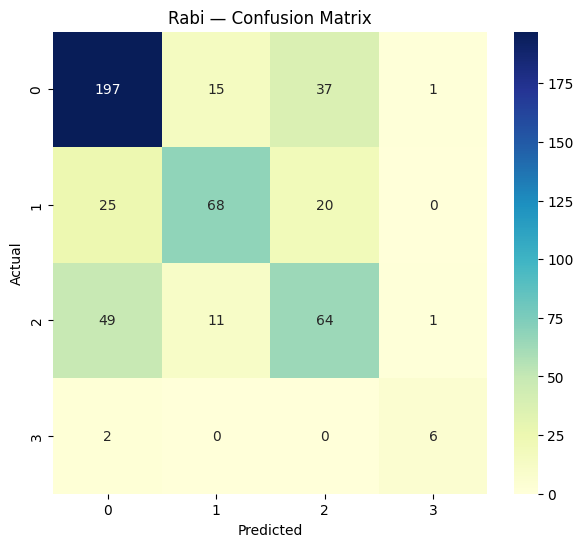

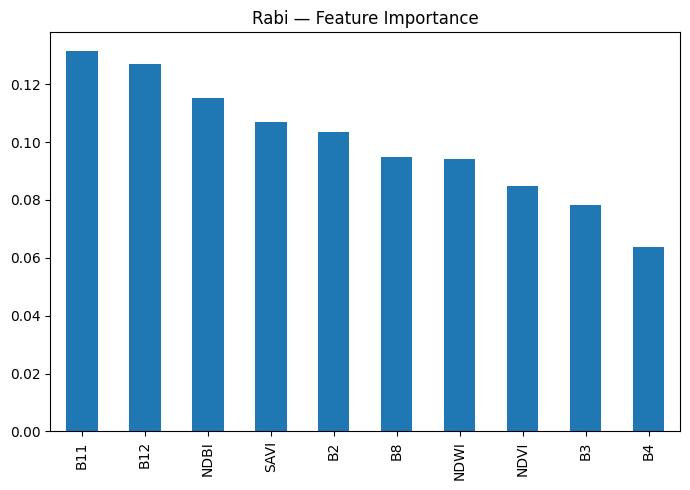

B11     0.131358
B12     0.126984
NDBI    0.115323
SAVI    0.106886
B2      0.103315
B8      0.094873
NDWI    0.094190
NDVI    0.084863
B3      0.078419
B4      0.063790
dtype: float64


In [7]:
cm = confusion_matrix(y_test, y_pred, labels=rf.classes_)
plt.figure(figsize=(7,6))
sns.heatmap(cm, annot=True, fmt="d", cmap="YlGnBu",
            xticklabels=rf.classes_, yticklabels=rf.classes_)
plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.title("Rabi — Confusion Matrix")
plt.show()

importances = pd.Series(rf.feature_importances_, index=feature_cols).sort_values(ascending=False)
plt.figure(figsize=(7,5))
importances.plot(kind="bar")
plt.title("Rabi — Feature Importance")
plt.tight_layout()
plt.show()
print(importances)


In [8]:
with rasterio.open(RABI_RASTER) as src:
    print("Raster band count:", src.count)
    print("Raster band descriptions:", src.descriptions)

print("\nTraining feature columns (%d):" % len(feature_cols))
print(feature_cols)

Raster band count: 6
Raster band descriptions: ('B2', 'B3', 'B4', 'B8', 'B11', 'B12')

Training feature columns (10):
['B11', 'B12', 'B2', 'B3', 'B4', 'B8', 'NDBI', 'NDVI', 'NDWI', 'SAVI']


In [9]:
with rasterio.open(RABI_RASTER) as src:
    img = src.read().astype("float32")   # (bands, H, W)
    profile = src.profile
    band_names = src.descriptions

n_bands, H, W = img.shape

SCALE_FACTOR = 10000.0  # Sentinel-2 SR reflectance scale factor

# Map band name -> 2D array, scaled to match training CSV (0-1 reflectance)
band_arrays = {name: img[i] / SCALE_FACTOR for i, name in enumerate(band_names)}

blue  = band_arrays["B2"]
green = band_arrays["B3"]
red   = band_arrays["B4"]
nir   = band_arrays["B8"]
swir1 = band_arrays["B11"]
swir2 = band_arrays["B12"]

eps = 1e-6
ndvi = (nir - red) / (nir + red + eps)
ndwi = (green - nir) / (green + nir + eps)
ndbi = (swir1 - nir) / (swir1 + nir + eps)
L = 0.5
savi = ((nir - red) / (nir + red + L + eps)) * (1 + L)

all_layers = {
    "B2": blue, "B3": green, "B4": red, "B8": nir, "B11": swir1, "B12": swir2,
    "NDVI": ndvi, "NDWI": ndwi, "NDBI": ndbi, "SAVI": savi
}

print("Model expects (in order):", feature_cols)
stack = np.stack([all_layers[name] for name in feature_cols], axis=0)  # (10, H, W)

img_reshaped = stack.reshape(len(feature_cols), -1).T   # (H*W, 10)

# Sanity check before predicting — these should now be close to CSV ranges
for i, name in enumerate(feature_cols):
    col = img_reshaped[:, i]
    print(f"{name}: min={np.nanmin(col):.4f}, max={np.nanmax(col):.4f}, mean={np.nanmean(col):.4f}")

valid_mask = ~np.any(np.isnan(img_reshaped) | np.isinf(img_reshaped), axis=1)
predictions = np.full(img_reshaped.shape[0], -1, dtype=np.int16)

from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
y_encoded = le.fit_transform(y)
rf_int = RandomForestClassifier(
    n_estimators=300, class_weight="balanced", random_state=42, n_jobs=-1
).fit(X, y_encoded)

preds_valid = rf_int.predict(img_reshaped[valid_mask])
predictions[valid_mask] = preds_valid

classified = predictions.reshape(H, W)
print("\nClassification done. Unique classes and pixel counts:")
print(np.unique(classified, return_counts=True))

Model expects (in order): ['B11', 'B12', 'B2', 'B3', 'B4', 'B8', 'NDBI', 'NDVI', 'NDWI', 'SAVI']
B11: min=0.0090, max=0.7244, mean=0.1560
B12: min=0.0030, max=0.8923, mean=0.0939
B2: min=0.0042, max=0.6932, mean=0.0422
B3: min=0.0111, max=0.7696, mean=0.0655
B4: min=0.0051, max=0.8256, mean=0.0504
B8: min=0.0025, max=0.8473, mean=0.3609
NDBI: min=-0.8338, max=0.8388, mean=-0.3771
NDVI: min=-0.8245, max=0.9544, mean=0.7308
NDWI: min=-0.8797, max=0.8873, mean=-0.6674
SAVI: min=-0.1835, max=0.7904, mean=0.5007

Classification done. Unique classes and pixel counts:
(array([-1,  0,  1,  2,  3], dtype=int16), array([19824057, 22650402,  1671375,  5469213,    83349]))


In [10]:
out_profile = profile.copy()
out_profile.update(count=1, dtype="int16", nodata=-1)

temp_path = os.path.join(OUT_DIR, "Karnal_Rabi_Classified_full.tif")
with rasterio.open(temp_path, "w", **out_profile) as dst:
    dst.write(classified.astype("int16"), 1)

# Clip to AOI boundary
with rasterio.open(temp_path) as src:
    boundary_reproj = boundary.to_crs(src.crs)
    out_image, out_transform = mask(src, boundary_reproj.geometry, crop=True, nodata=-1)
    out_meta = src.meta.copy()
    out_meta.update({
        "height": out_image.shape[1],
        "width": out_image.shape[2],
        "transform": out_transform
    })

final_path = os.path.join(OUT_DIR, "Karnal_Rabi_Classified.tif")
with rasterio.open(final_path, "w", **out_meta) as dst:
    dst.write(out_image)

print("Saved:", final_path)

Saved: /kaggle/working/Karnal_Rabi_Classified.tif


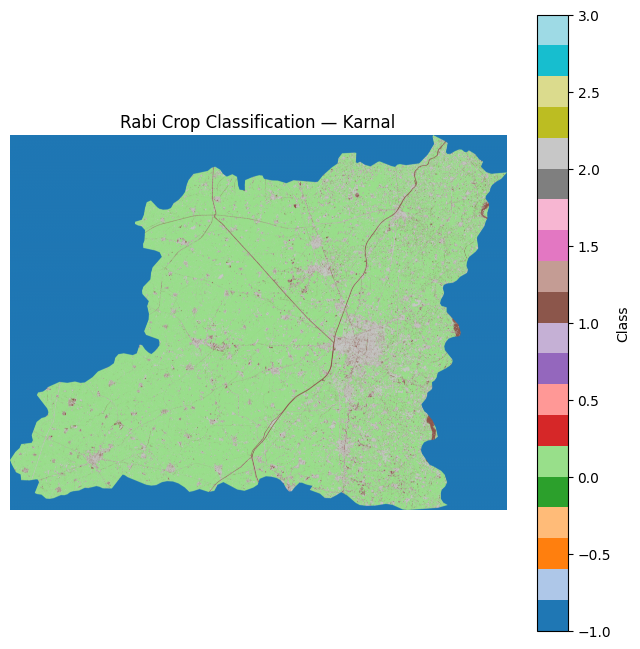

['/kaggle/working/label_encoder_rabi.pkl']

In [11]:
plt.figure(figsize=(8,8))
plt.imshow(out_image[0], cmap="tab20")
plt.title("Rabi Crop Classification — Karnal")
plt.colorbar(label="Class")
plt.axis("off")
plt.show()

joblib.dump(rf_int, os.path.join(OUT_DIR, "rf_rabi_model.pkl"))
joblib.dump(le, os.path.join(OUT_DIR, "label_encoder_rabi.pkl"))

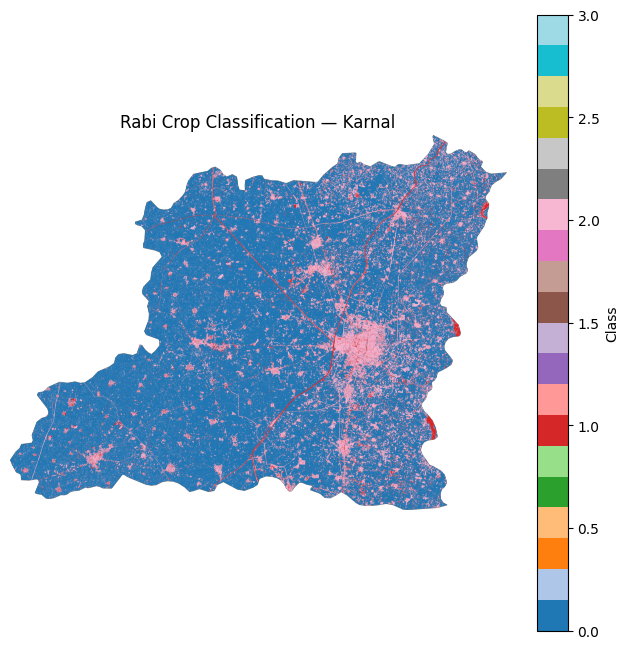

In [12]:
import numpy as np
import matplotlib.pyplot as plt

masked = np.ma.masked_equal(out_image[0], -1)  # hide nodata

fig, ax = plt.subplots(figsize=(8,8))
im = ax.imshow(masked, cmap="tab20")
ax.set_title("Rabi Crop Classification — Karnal")
ax.axis("off")

cbar = plt.colorbar(im, ax=ax, label="Class")
plt.show()

{0: np.int64(0), 1: np.int64(1), 2: np.int64(2), 3: np.int64(3)}


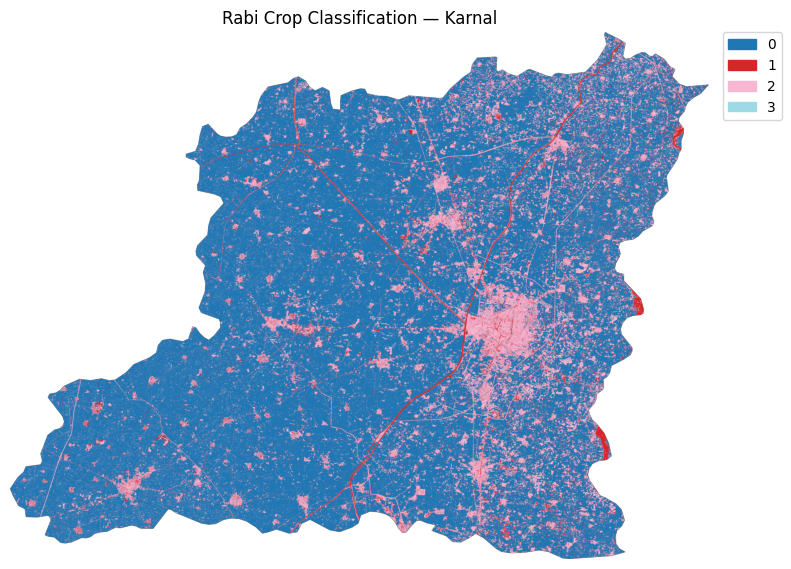

In [13]:
class_names = le.classes_   # original string labels, e.g. ['Fallow','Urban','Wheat','Mustard']
print(dict(enumerate(class_names)))

# Discrete legend instead of continuous colorbar
from matplotlib.colors import ListedColormap, BoundaryNorm
import matplotlib.patches as mpatches

n_classes = len(class_names)
cmap = plt.get_cmap("tab20", n_classes)

fig, ax = plt.subplots(figsize=(8,8))
im = ax.imshow(masked, cmap=cmap, vmin=-0.5, vmax=n_classes-0.5)
ax.set_title("Rabi Crop Classification — Karnal")
ax.axis("off")

patches = [mpatches.Patch(color=cmap(i), label=class_names[i]) for i in range(n_classes)]
ax.legend(handles=patches, bbox_to_anchor=(1.02, 1), loc="upper left", borderaxespad=0)
plt.tight_layout()
plt.show()

In [14]:
pixel_size_m = abs(out_meta["transform"][0])  # e.g. 10m for Sentinel-2
pixel_area_ha = (pixel_size_m ** 2) / 10000     # sq meters -> hectares

unique, counts = np.unique(out_image[0][out_image[0] != -1], return_counts=True)
area_df = pd.DataFrame({
    "Class": [class_names[int(u)] for u in unique],
    "Pixels": counts,
    "Area_ha": counts * pixel_area_ha
}).sort_values("Area_ha", ascending=False)
print(area_df)

   Class    Pixels       Area_ha
0      0  22637126  1.826749e-05
2      2   5466119  4.410996e-06
1      1   1669949  1.347599e-06
3      3     83315  6.723273e-08


In [15]:
import rasterio
from rasterio.warp import reproject, Resampling
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# EDIT THIS to your actual Kharif dataset path
KHARIF_PATH = "/kaggle/input/datasets/minatonamikaze20/kharif-class/Karnal_RF_Classification.tif"
RABI_PATH   = final_path   # from Cell 7, already clipped to AOI

with rasterio.open(RABI_PATH) as rabi_src:
    rabi_arr = rabi_src.read(1)
    rabi_profile = rabi_src.profile
    rabi_transform = rabi_src.transform
    rabi_crs = rabi_src.crs
    rabi_shape = rabi_arr.shape

with rasterio.open(KHARIF_PATH) as kharif_src:
    print("Kharif CRS:", kharif_src.crs, "shape:", kharif_src.shape)
    print("Rabi   CRS:", rabi_crs, "shape:", rabi_shape)

    # Resample/reproject Kharif onto Rabi's exact grid so pixels line up 1:1
    kharif_aligned = np.empty(rabi_shape, dtype=np.int16)
    reproject(
        source=rasterio.band(kharif_src, 1),
        destination=kharif_aligned,
        src_transform=kharif_src.transform,
        src_crs=kharif_src.crs,
        dst_transform=rabi_transform,
        dst_crs=rabi_crs,
        resampling=Resampling.nearest   # nearest-neighbor: classes are categorical, never interpolate
    )

print("Aligned shapes match:", kharif_aligned.shape == rabi_arr.shape)

Kharif CRS: EPSG:4326 shape: (6122, 8118)
Rabi   CRS: EPSG:4326 shape: (6122, 8118)
Aligned shapes match: True


In [16]:
rabi_names = {
    0: "Wheat",
    1: "Mustard",
    2: "Fallow",
    3: "Urban",
}

# CORRECTED to match Phase 1 report exactly
kharif_names = {
    0: "Agriculture",
    1: "Water",
    2: "Built-up",
    3: "Dense Vegetation",   # paddy/rice-dominated class per report text
}

rabi_classes_in_data = sorted(train_df[LABEL_COL].unique())
missing_rabi = [c for c in rabi_classes_in_data if c not in rabi_names]
assert not missing_rabi, f"rabi_names is missing labels for class codes: {missing_rabi}. Fix rabi_names above."

print("Rabi classes:", rabi_names)
print("Kharif classes:", kharif_names)

Rabi classes: {0: 'Wheat', 1: 'Mustard', 2: 'Fallow', 3: 'Urban'}
Kharif classes: {0: 'Agriculture', 1: 'Water', 2: 'Built-up', 3: 'Dense Vegetation'}


In [17]:
valid = (rabi_arr != -1) & (kharif_aligned != -1) & (kharif_aligned >= 0)

kharif_flat = kharif_aligned[valid]
rabi_flat = rabi_arr[valid]

kharif_labels = np.array([kharif_names.get(v, f"Unknown_{v}") for v in kharif_flat])
rabi_labels = np.array([rabi_names.get(v, f"Unknown_{v}") for v in rabi_flat])

rotation_matrix = pd.crosstab(
    kharif_labels, rabi_labels,
    rownames=["Kharif"], colnames=["Rabi"]
)
print(rotation_matrix)

bounds = rasterio.open(RABI_PATH).bounds
center_lat = (bounds.top + bounds.bottom) / 2

pixel_size_deg = abs(rabi_profile["transform"][0])
meters_per_deg_lat = 111320
meters_per_deg_lon = 111320 * np.cos(np.radians(center_lat))

pixel_width_m  = pixel_size_deg * meters_per_deg_lon
pixel_height_m = pixel_size_deg * meters_per_deg_lat
pixel_area_ha = (pixel_width_m * pixel_height_m) / 10000

print(f"Pixel size: {pixel_width_m:.2f}m x {pixel_height_m:.2f}m = {pixel_area_ha:.6f} ha")

rotation_matrix_ha = rotation_matrix * pixel_area_ha
print("\nArea (hectares):")
print(rotation_matrix_ha.round(1))

Rabi          Fallow  Mustard  Urban     Wheat
Kharif                                        
Agriculture    70390    16485    257   1348276
Built-up      851651   261494  16037   3076622
Water        4544078  1391970  67021  18212228
Pixel size: 8.68m x 10.00m = 0.008685 ha

Area (hectares):
Rabi          Fallow  Mustard  Urban     Wheat
Kharif                                        
Agriculture    611.3    143.2    2.2   11709.3
Built-up      7396.3   2271.0  139.3   26719.3
Water        39463.6  12088.7  582.1  158166.2


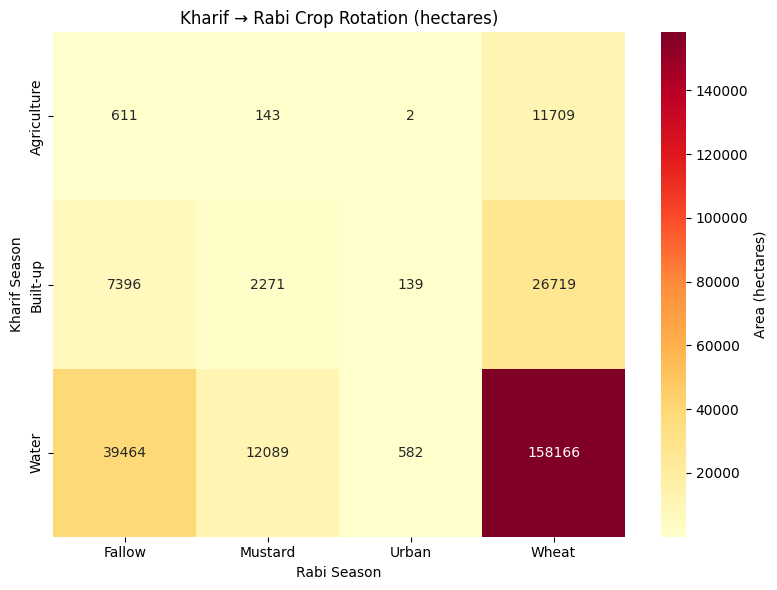

In [18]:
import seaborn as sns

plt.figure(figsize=(8,6))
sns.heatmap(rotation_matrix_ha, annot=True, fmt=".0f", cmap="YlOrRd",
            cbar_kws={"label": "Area (hectares)"})
plt.title("Kharif → Rabi Crop Rotation (hectares)")
plt.ylabel("Kharif Season")
plt.xlabel("Rabi Season")
plt.tight_layout()
plt.show()

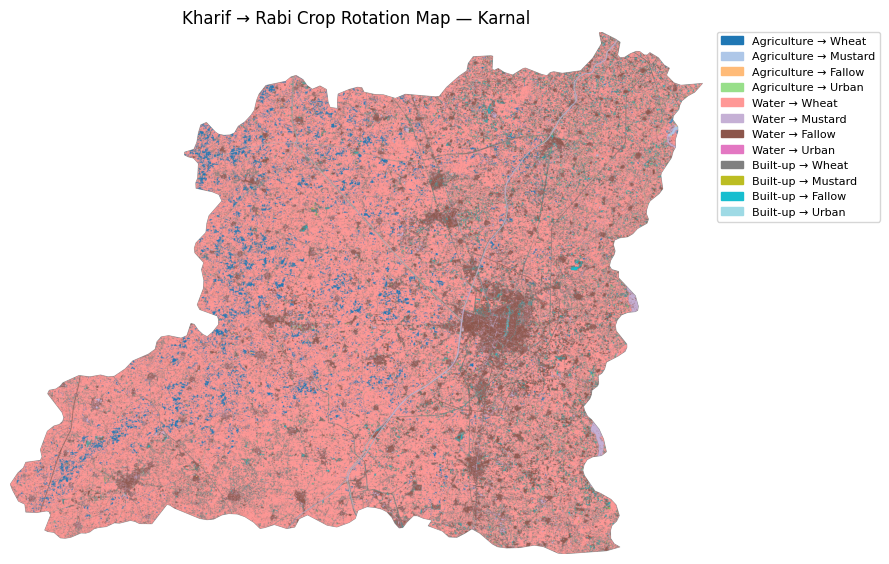

In [19]:
# Combine both seasons into one code per pixel: kharif*100 + rabi
combined = np.full(rabi_arr.shape, -1, dtype=np.int32)
combined[valid] = kharif_flat.astype(np.int32) * 100 + rabi_flat.astype(np.int32)

unique_combos = np.unique(combined[combined != -1])
combo_labels = {
    c: f"{kharif_names.get(c//100, c//100)} → {rabi_names.get(c%100, c%100)}"
    for c in unique_combos
}

# Remap combo codes to sequential ints for clean plotting
combo_to_idx = {c: i for i, c in enumerate(unique_combos)}
rotation_map = np.full(combined.shape, -1, dtype=np.int16)
for c, idx in combo_to_idx.items():
    rotation_map[combined == c] = idx

masked_rotation = np.ma.masked_equal(rotation_map, -1)

n_combos = len(unique_combos)
cmap = plt.get_cmap("tab20", n_combos)

fig, ax = plt.subplots(figsize=(9,9))
im = ax.imshow(masked_rotation, cmap=cmap, vmin=-0.5, vmax=n_combos-0.5)
ax.set_title("Kharif → Rabi Crop Rotation Map — Karnal")
ax.axis("off")

patches = [mpatches.Patch(color=cmap(idx), label=combo_labels[c])
           for c, idx in combo_to_idx.items()]
ax.legend(handles=patches, bbox_to_anchor=(1.02, 1), loc="upper left",
          borderaxespad=0, fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "Kharif_Rabi_Rotation_Map.png"), dpi=150, bbox_inches="tight")
plt.show()

In [20]:
rotation_matrix_ha.to_csv(os.path.join(OUT_DIR, "rotation_matrix_hectares.csv"))

with rasterio.open(
    os.path.join(OUT_DIR, "Kharif_Rabi_Rotation_Map.tif"), "w", **{
        **rabi_profile, "dtype": "int16", "nodata": -1
    }
) as dst:
    dst.write(rotation_map.astype("int16"), 1)

print("Saved rotation matrix CSV, rotation map PNG, and rotation map GeoTIFF to", OUT_DIR)

Saved rotation matrix CSV, rotation map PNG, and rotation map GeoTIFF to /kaggle/working


In [21]:
print(train_df[LABEL_COL].unique())
print(train_df[LABEL_COL].value_counts())

[0 1 2 3]
class
0    1000
2     500
1     452
3      30
Name: count, dtype: int64


In [22]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.colors import ListedColormap
import numpy as np

plt.rcParams.update({
    "font.family": "serif",
    "font.size": 11,
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
    "figure.dpi": 150,
    "savefig.dpi": 300,
    "savefig.bbox": "tight"
})

CROP_COLORS = {
    "Wheat":   "#F4C430",
    "Mustard": "#7FB800",
    "Fallow":  "#C2A878",
    "Urban":   "#8C8C8C",
    "Rice":    "#1E7D32",
    "Water":   "#3182BD",
}

def north_arrow(ax, x=0.93, y=0.93, size=0.05):
    ax.annotate("N", xy=(x, y), xytext=(x, y-size),
                xycoords="axes fraction",
                arrowprops=dict(facecolor="black", width=4, headwidth=12),
                ha="center", fontsize=12, fontweight="bold")

def simple_scalebar(ax, length_km, center_lat, location=(0.05, 0.05)):
    """Manual scale bar for lat/lon (EPSG:4326) axes — no external package needed."""
    km_per_deg_lon = 111.32 * np.cos(np.radians(center_lat))
    bar_len_deg = length_km / km_per_deg_lon

    xlim = ax.get_xlim(); ylim = ax.get_ylim()
    x0 = xlim[0] + location[0] * (xlim[1] - xlim[0])
    y0 = ylim[0] + location[1] * (ylim[1] - ylim[0])

    ax.plot([x0, x0 + bar_len_deg], [y0, y0], color="black", linewidth=3,
             solid_capstyle="butt", transform=ax.transData)
    ax.text(x0 + bar_len_deg/2, y0 + 0.015*(ylim[1]-ylim[0]), f"{length_km} km",
             ha="center", fontsize=9, fontweight="bold")

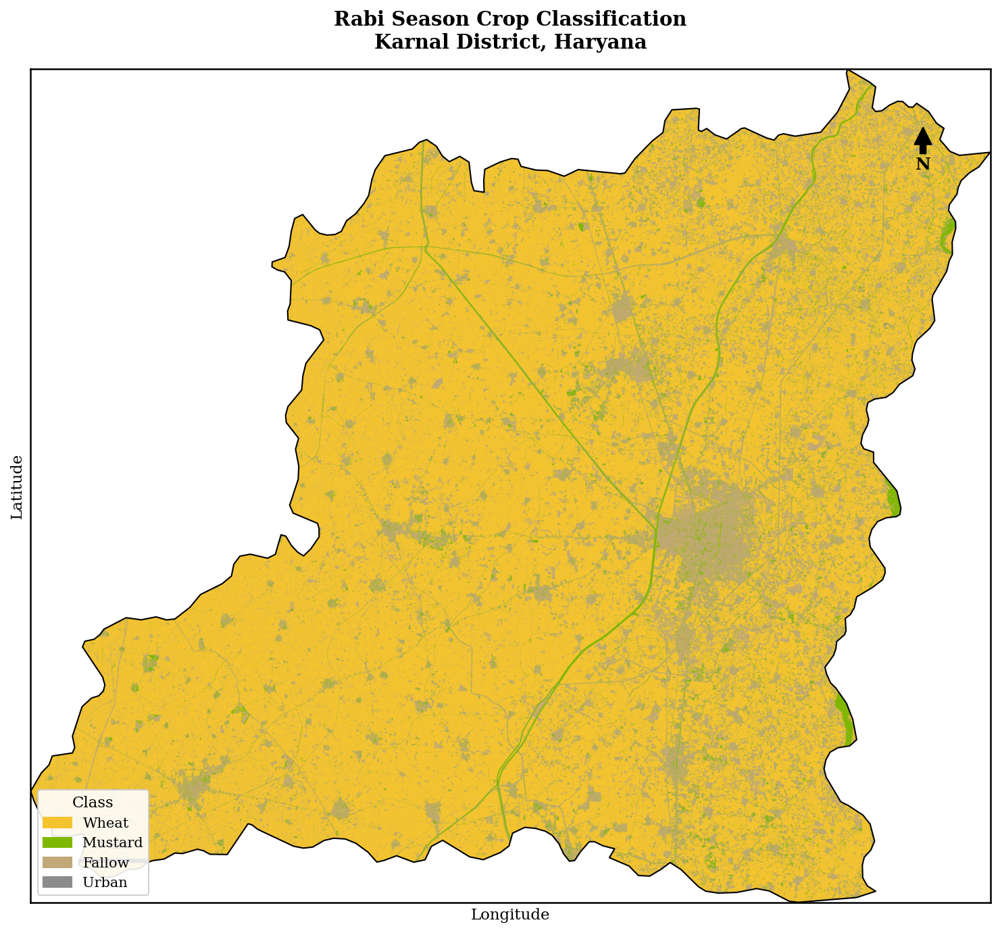

In [23]:
with rasterio.open(final_path) as src:
    rabi_data = src.read(1)
    rabi_bounds = src.bounds
    rabi_transform = src.transform

masked_rabi = np.ma.masked_equal(rabi_data, -1)

# EDIT: confirm rabi_names dict is finalized (real crop names, not 0/1/2/3)
classes_present = sorted([c for c in np.unique(rabi_data) if c != -1])
colors = [CROP_COLORS.get(rabi_names[c], "#CCCCCC") for c in classes_present]
cmap = ListedColormap(colors)

fig, ax = plt.subplots(figsize=(10, 10))
extent = [rabi_bounds.left, rabi_bounds.right, rabi_bounds.bottom, rabi_bounds.top]
im = ax.imshow(masked_rabi, cmap=cmap, extent=extent,
                vmin=min(classes_present)-0.5, vmax=max(classes_present)+0.5)

boundary.to_crs(rabi_crs).boundary.plot(ax=ax, color="black", linewidth=1)

ax.set_title("Rabi Season Crop Classification\nKarnal District, Haryana", pad=15)
ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude")

patches = [mpatches.Patch(color=CROP_COLORS.get(rabi_names[c], "#CCCCCC"), label=rabi_names[c])
           for c in classes_present]
ax.legend(handles=patches, loc="lower left", frameon=True, framealpha=0.9,
          title="Class", fontsize=10, title_fontsize=11)

north_arrow(ax)
center_lat = (rabi_bounds.top + rabi_bounds.bottom) / 2
simple_scalebar(ax, length_km=5, center_lat=center_lat)

ax.set_xticks([]); ax.set_yticks([])
for spine in ax.spines.values():
    spine.set_visible(True); spine.set_linewidth(1.2)

plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "Fig_Rabi_Classification_Map.png"))
plt.savefig(os.path.join(OUT_DIR, "Fig_Rabi_Classification_Map.pdf"))
plt.show()

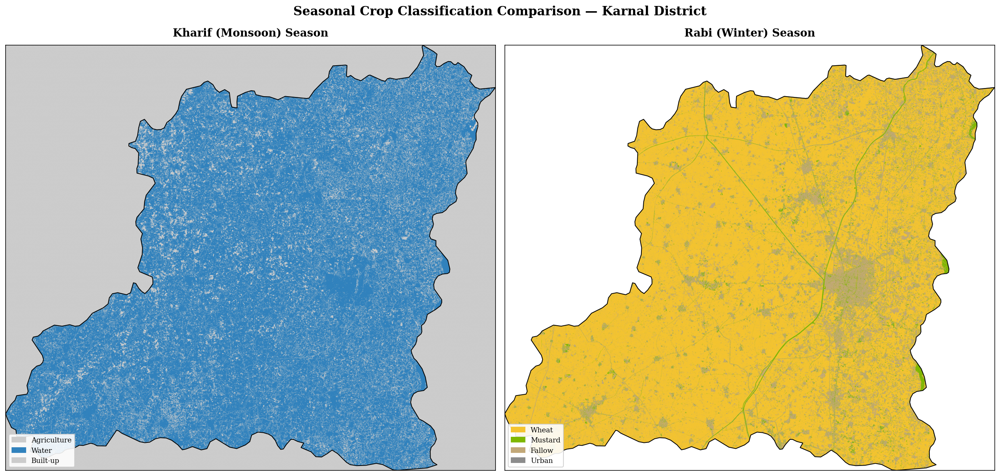

In [24]:
with rasterio.open(KHARIF_PATH) as src:
    kharif_disp = src.read(1)
    kharif_bounds = src.bounds

masked_kharif = np.ma.masked_equal(kharif_disp, -1)

kharif_classes_present = sorted([c for c in np.unique(kharif_disp) if c != -1])
kharif_colors = [CROP_COLORS.get(kharif_names[c], "#CCCCCC") for c in kharif_classes_present]
kharif_cmap = ListedColormap(kharif_colors)

fig, axes = plt.subplots(1, 2, figsize=(18, 9))

extent_k = [kharif_bounds.left, kharif_bounds.right, kharif_bounds.bottom, kharif_bounds.top]
axes[0].imshow(masked_kharif, cmap=kharif_cmap, extent=extent_k,
               vmin=min(kharif_classes_present)-0.5, vmax=max(kharif_classes_present)+0.5)
boundary.to_crs(rabi_crs).boundary.plot(ax=axes[0], color="black", linewidth=1)
axes[0].set_title("Kharif (Monsoon) Season", pad=12)
kp = [mpatches.Patch(color=CROP_COLORS.get(kharif_names[c], "#CCCCCC"), label=kharif_names[c])
      for c in kharif_classes_present]
axes[0].legend(handles=kp, loc="lower left", fontsize=9, framealpha=0.9)
axes[0].set_xticks([]); axes[0].set_yticks([])

axes[1].imshow(masked_rabi, cmap=cmap, extent=extent,
               vmin=min(classes_present)-0.5, vmax=max(classes_present)+0.5)
boundary.to_crs(rabi_crs).boundary.plot(ax=axes[1], color="black", linewidth=1)
axes[1].set_title("Rabi (Winter) Season", pad=12)
axes[1].legend(handles=patches, loc="lower left", fontsize=9, framealpha=0.9)
axes[1].set_xticks([]); axes[1].set_yticks([])

fig.suptitle("Seasonal Crop Classification Comparison — Karnal District",
             fontsize=16, fontweight="bold", y=0.98)

plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "Fig_Kharif_vs_Rabi_Panel.png"))
plt.savefig(os.path.join(OUT_DIR, "Fig_Kharif_vs_Rabi_Panel.pdf"))
plt.show()

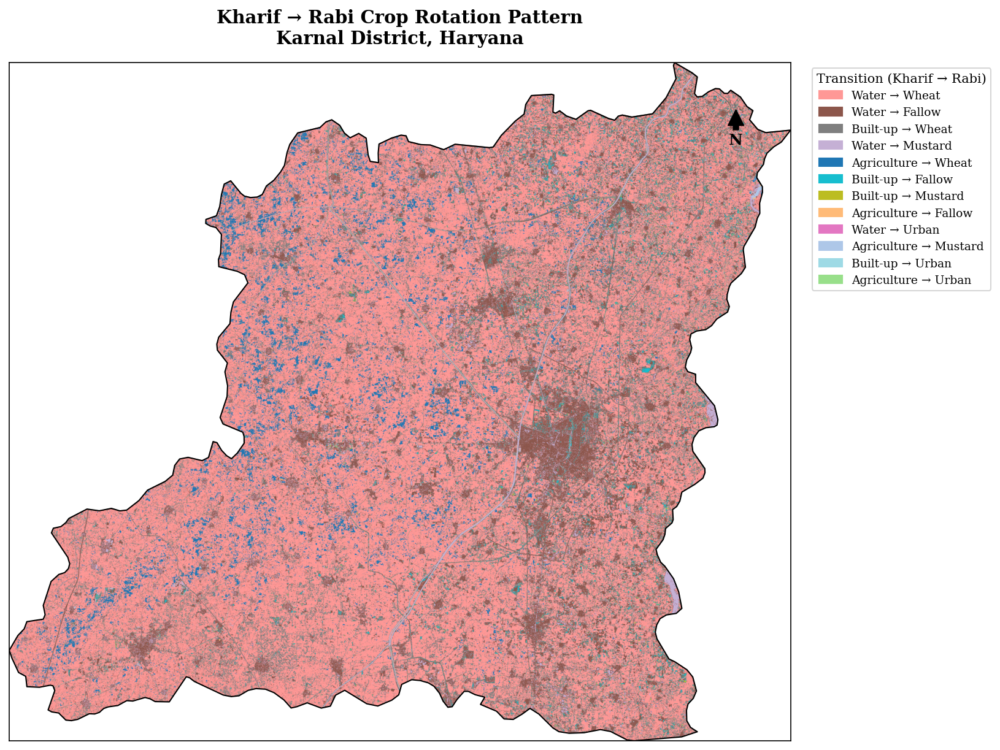

In [25]:
fig, ax = plt.subplots(figsize=(11, 10))

n_combos = len(unique_combos)
rotation_cmap = plt.get_cmap("tab20", n_combos)

im = ax.imshow(masked_rotation, cmap=rotation_cmap, extent=extent,
               vmin=-0.5, vmax=n_combos-0.5)
boundary.to_crs(rabi_crs).boundary.plot(ax=ax, color="black", linewidth=1)

ax.set_title("Kharif → Rabi Crop Rotation Pattern\nKarnal District, Haryana", pad=15)

# Sort legend by area (largest transitions first) for readability
combo_areas = {c: np.sum(combined == c) for c in unique_combos}
sorted_combos = sorted(unique_combos, key=lambda c: -combo_areas[c])

patches_r = [mpatches.Patch(color=rotation_cmap(combo_to_idx[c]), label=combo_labels[c])
             for c in sorted_combos]
ax.legend(handles=patches_r, bbox_to_anchor=(1.02, 1), loc="upper left",
          fontsize=9, title="Transition (Kharif → Rabi)", title_fontsize=10)

north_arrow(ax)
ax.set_xticks([]); ax.set_yticks([])

plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "Fig_Rotation_Map.png"))
plt.savefig(os.path.join(OUT_DIR, "Fig_Rotation_Map.pdf"))
plt.show()

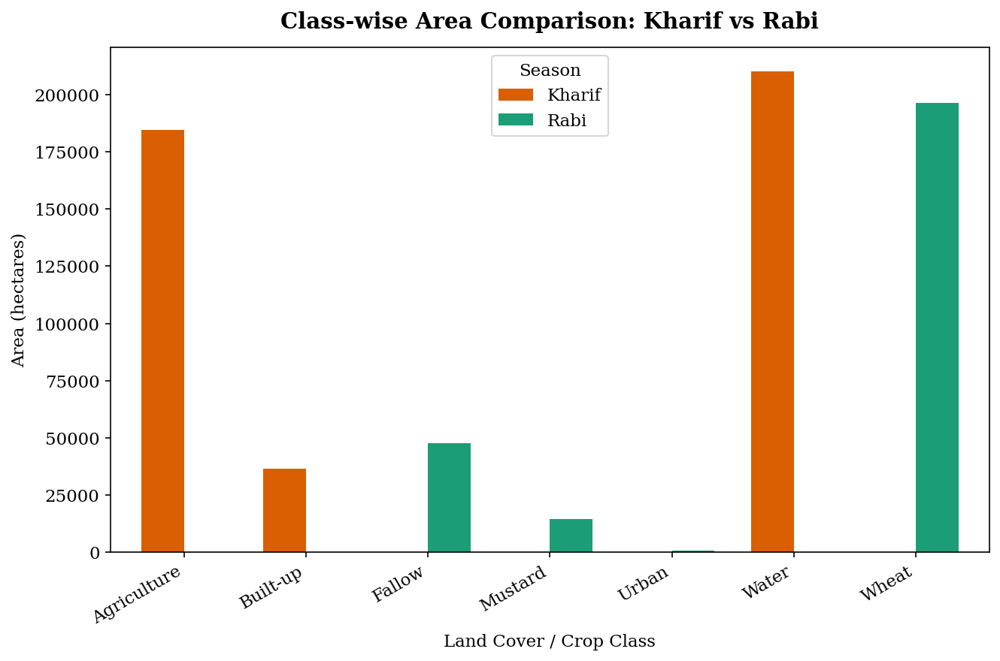

               Kharif      Rabi
Agriculture  184630.9       0.0
Built-up      36525.8       0.0
Fallow            0.0   47471.1
Mustard           0.0   14502.9
Urban             0.0     723.6
Water        210454.7       0.0
Wheat             0.0  196594.7


In [26]:
kharif_pixel_area_ha = pixel_area_ha  # same grid, already computed

kharif_areas = pd.Series(kharif_disp[kharif_disp != -1]).map(kharif_names).value_counts() * kharif_pixel_area_ha
rabi_areas = pd.Series(rabi_data[rabi_data != -1]).map(rabi_names).value_counts() * pixel_area_ha

area_compare = pd.DataFrame({"Kharif": kharif_areas, "Rabi": rabi_areas}).fillna(0)

fig, ax = plt.subplots(figsize=(9, 6))
area_compare.plot(kind="bar", ax=ax, color=["#D95F02", "#1B9E77"], width=0.7)
ax.set_ylabel("Area (hectares)")
ax.set_xlabel("Land Cover / Crop Class")
ax.set_title("Class-wise Area Comparison: Kharif vs Rabi", pad=12)
ax.legend(title="Season")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "Fig_Area_Comparison.png"))
plt.show()

print(area_compare.round(1))

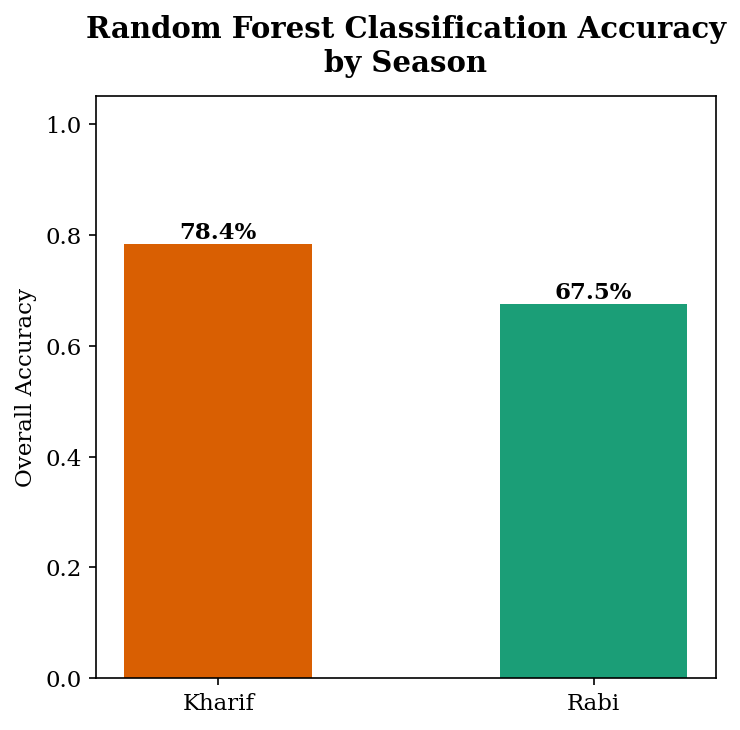

In [27]:
kharif_accuracy = 0.7836   # from Phase 1 report: 78.36%
rabi_accuracy = accuracy_score(y_test, y_pred)

fig, ax = plt.subplots(figsize=(5, 5))
bars = ax.bar(["Kharif", "Rabi"], [kharif_accuracy, rabi_accuracy],
              color=["#D95F02", "#1B9E77"], width=0.5)
for bar, val in zip(bars, [kharif_accuracy, rabi_accuracy]):
    ax.text(bar.get_x()+bar.get_width()/2, val+0.01, f"{val:.1%}",
            ha="center", fontweight="bold")
ax.set_ylim(0, 1.05)
ax.set_ylabel("Overall Accuracy")
ax.set_title("Random Forest Classification Accuracy\nby Season", pad=12)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "Fig_Accuracy_Comparison.png"))
plt.show()

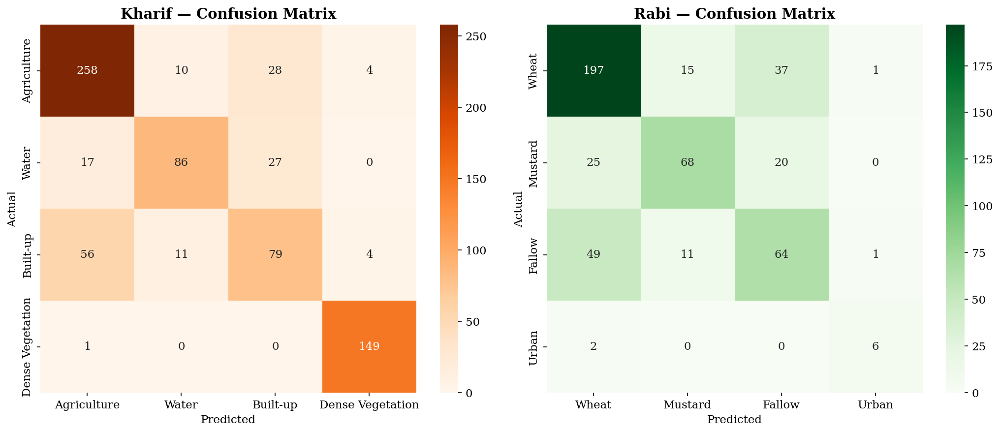

In [28]:
kharif_cm = np.array([
    [258, 10, 28,  4],
    [ 17, 86, 27,  0],
    [ 56, 11, 79,  4],
    [  1,  0,  0, 149]
])  # from Phase 1 report Table 6.4/confusion matrix

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

kharif_label_order = [kharif_names[c] for c in sorted(kharif_names.keys())]
sns.heatmap(kharif_cm, annot=True, fmt="d", cmap="Oranges", ax=axes[0],
            xticklabels=kharif_label_order, yticklabels=kharif_label_order)
axes[0].set_title("Kharif — Confusion Matrix")
axes[0].set_xlabel("Predicted"); axes[0].set_ylabel("Actual")

rabi_label_order = [rabi_names[c] for c in sorted(rabi_names.keys())]
sns.heatmap(cm, annot=True, fmt="d", cmap="Greens", ax=axes[1],
            xticklabels=rabi_label_order, yticklabels=rabi_label_order)
axes[1].set_title("Rabi — Confusion Matrix")
axes[1].set_xlabel("Predicted"); axes[1].set_ylabel("Actual")

plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "Fig_Confusion_Matrices_Combined.png"))
plt.show()

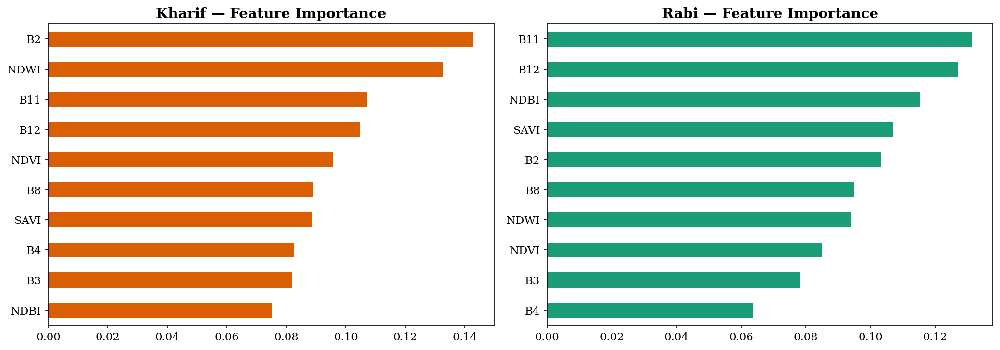

In [29]:
kharif_feature_cols = ["B2", "NDWI", "B11", "B12", "NDVI", "B8", "SAVI", "B4", "B3", "NDBI"]
kharif_importance_values = [0.1427, 0.1328, 0.1070, 0.1048, 0.0955, 0.0890, 0.0886, 0.0826, 0.0818, 0.0752]

kharif_importances = pd.Series(kharif_importance_values, index=kharif_feature_cols)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
kharif_importances.sort_values().plot(kind="barh", ax=axes[0], color="#D95F02")
axes[0].set_title("Kharif — Feature Importance")

importances.sort_values().plot(kind="barh", ax=axes[1], color="#1B9E77")
axes[1].set_title("Rabi — Feature Importance")

plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "Fig_Feature_Importance_Combined.png"))
plt.show()

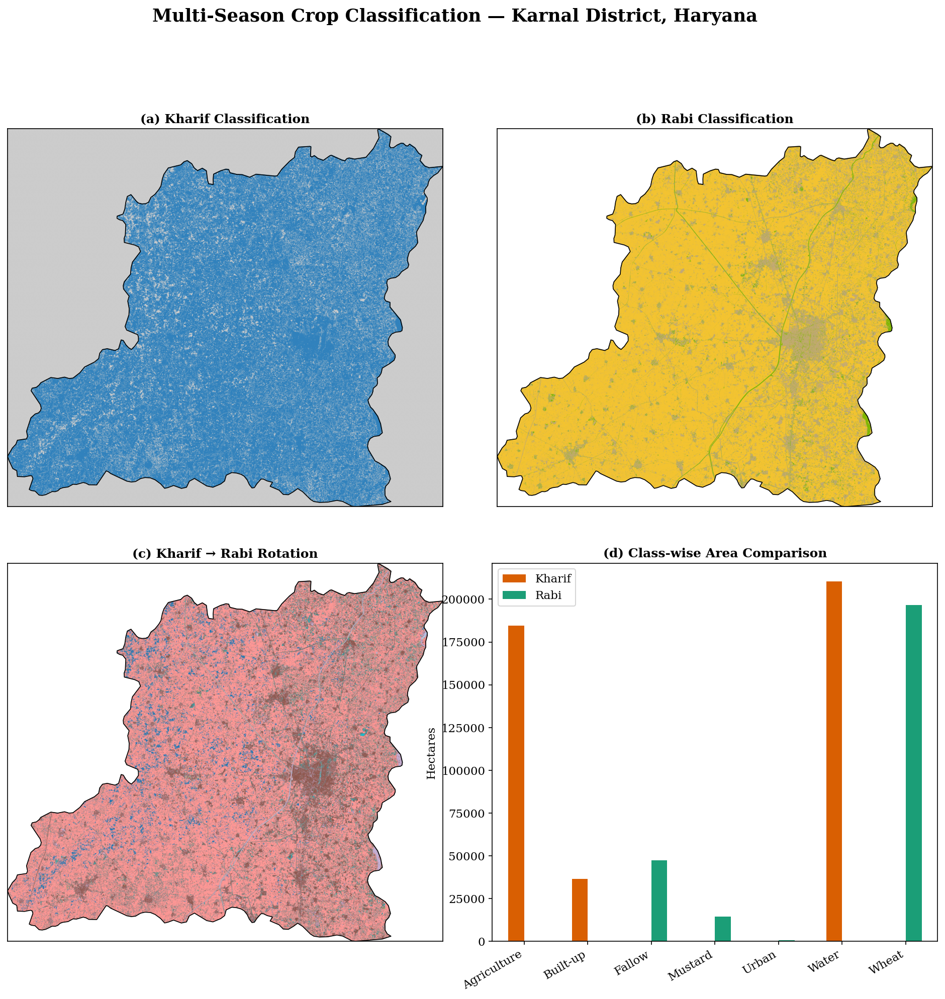

All publication figures saved to: /kaggle/working


In [30]:
fig = plt.figure(figsize=(16, 14))
gs = fig.add_gridspec(2, 2, hspace=0.15, wspace=0.1)

ax1 = fig.add_subplot(gs[0, 0])
ax1.imshow(masked_kharif, cmap=kharif_cmap, extent=extent_k,
           vmin=min(kharif_classes_present)-0.5, vmax=max(kharif_classes_present)+0.5)
boundary.to_crs(rabi_crs).boundary.plot(ax=ax1, color="black", linewidth=0.8)
ax1.set_title("(a) Kharif Classification", fontsize=12)
ax1.set_xticks([]); ax1.set_yticks([])

ax2 = fig.add_subplot(gs[0, 1])
ax2.imshow(masked_rabi, cmap=cmap, extent=extent,
           vmin=min(classes_present)-0.5, vmax=max(classes_present)+0.5)
boundary.to_crs(rabi_crs).boundary.plot(ax=ax2, color="black", linewidth=0.8)
ax2.set_title("(b) Rabi Classification", fontsize=12)
ax2.set_xticks([]); ax2.set_yticks([])

ax3 = fig.add_subplot(gs[1, 0])
ax3.imshow(masked_rotation, cmap=rotation_cmap, extent=extent, vmin=-0.5, vmax=n_combos-0.5)
boundary.to_crs(rabi_crs).boundary.plot(ax=ax3, color="black", linewidth=0.8)
ax3.set_title("(c) Kharif → Rabi Rotation", fontsize=12)
ax3.set_xticks([]); ax3.set_yticks([])

ax4 = fig.add_subplot(gs[1, 1])
area_compare.plot(kind="bar", ax=ax4, color=["#D95F02", "#1B9E77"], legend=True)
ax4.set_title("(d) Class-wise Area Comparison", fontsize=12)
ax4.set_ylabel("Hectares")
plt.setp(ax4.get_xticklabels(), rotation=30, ha="right")

fig.suptitle("Multi-Season Crop Classification — Karnal District, Haryana",
             fontsize=17, fontweight="bold", y=0.995)

plt.savefig(os.path.join(OUT_DIR, "Fig_Summary_Panel.png"), dpi=300, bbox_inches="tight")
plt.savefig(os.path.join(OUT_DIR, "Fig_Summary_Panel.pdf"), bbox_inches="tight")
plt.show()

print("All publication figures saved to:", OUT_DIR)